# Анализ розничных продаж Superstore

**Задача:** выявить факторы, влияющие на прибыль, и найти точки роста для бизнеса.

**Данные:** Superstore — 9994 транзакции за 2014–2017 гг.
Колонки: Order ID, Order Date, Ship Date, Ship Mode, Customer, Segment, Country, City, State, Region, Product, Category, Sub-Category, Sales, Quantity, Discount, Profit.

**Гипотезы:**
1. Некоторые подкатегории приносят убыток при высоких продажах.
2. Furniture — самая низкомаржинальная категория.
3. Technology — самая прибыльная категория.
4. После скидки 20–30% средняя прибыль отрицательна.
5. Большинство убыточных сделок — со скидкой >30%.
6. Высокие продажи ≠ высокая прибыль по штатам.
7. Есть стабильно убыточные штаты.
8. Продажи растут год к году.
9. Пик продаж — ноябрь–декабрь.
10. Corporate и Home Office прибыльнее Consumer.
11. Discount и Sales — главные признаки для модели.
12. R² модели > 0.7.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', None)

## 1. Загрузка и первичный осмотр

На этом этапе:
- загружаем файл `superstore.csv`;
- смотрим первые строки;
- проверяем размер, типы колонок и базовую статистику.

In [8]:
df = pd.read_csv('Superstore.csv', encoding='latin1')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2013-152156,09-11-2013,12-11-2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2013-152156,09-11-2013,12-11-2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2013-138688,13-06-2013,17-06-2013,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2012-108966,11-10-2012,18-10-2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2012-108966,11-10-2012,18-10-2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 2. Очистка данных

На этом этапе:
- проверяем пропуски и дубликаты;
- преобразуем даты в правильный формат;
- создаём новые признаки (например, время доставки).

In [9]:
print("Пропуски в данных:")
print(df.isnull().sum())

Пропуски в данных:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [10]:
print(f"Дубликатов до очистки: {df.duplicated().sum()}")
df = df.drop_duplicates()
print(f"Строк после удаления дубликатов: {df.shape[0]}")

Дубликатов до очистки: 0
Строк после удаления дубликатов: 9994


In [12]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%d-%m-%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%d-%m-%Y')

df[['Order Date', 'Ship Date']].head()

,Order Date,Ship Date
0,2013-11-09,2013-11-12
1,2013-11-09,2013-11-12
2,2013-06-13,2013-06-17
3,2012-10-11,2012-10-18
4,2012-10-11,2012-10-18


In [13]:
df['Ship Delay'] = (df['Ship Date'] - df['Order Date']).dt.days

print(f"Среднее время доставки: {df['Ship Delay'].mean():.1f} дней")
print(f"Максимальное время доставки: {df['Ship Delay'].max()} дней")

Среднее время доставки: 4.0 дней
Максимальное время доставки: 7 дней


## 3. Разведочный анализ (EDA)

### 3.1 Продажи и прибыль по категориям

**Гипотеза 2:** Furniture — самая низкомаржинальная категория.
**Гипотеза 3:** Technology — самая прибыльная.

                       Sales       Profit     Margin
Category                                            
Technology       836154.0330  145454.9481  17.395712
Office Supplies  719047.0320  122490.8008  17.035158
Furniture        741999.7953   18451.2728   2.486695


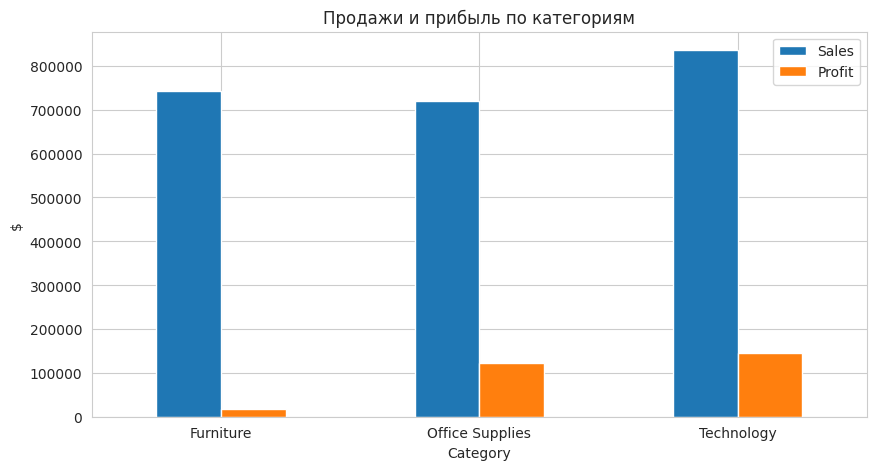

In [14]:
cat = df.groupby('Category')[['Sales', 'Profit']].sum()
cat['Margin'] = cat['Profit'] / cat['Sales'] * 100
print(cat.sort_values('Profit', ascending=False))

cat[['Sales', 'Profit']].plot(kind='bar', figsize=(10, 5))
plt.title('Продажи и прибыль по категориям')
plt.ylabel('$')
plt.xticks(rotation=0)
plt.show()

**Вывод:** Technology лидирует по прибыли (около $145,000) и марже (около 17%).
Furniture имеет самую низкую маржу (около 2.5%) при почти таких же продажах, как у Technology.
Гипотеза 2 подтвердилась (Furniture — самая низкомаржинальная), Гипотеза 3 подтвердилась (Technology — самая прибыльная).

### 3.2 Топ-10 убыточных подкатегорий

**Гипотеза 1:** Некоторые подкатегории приносят убыток при высоких продажах.

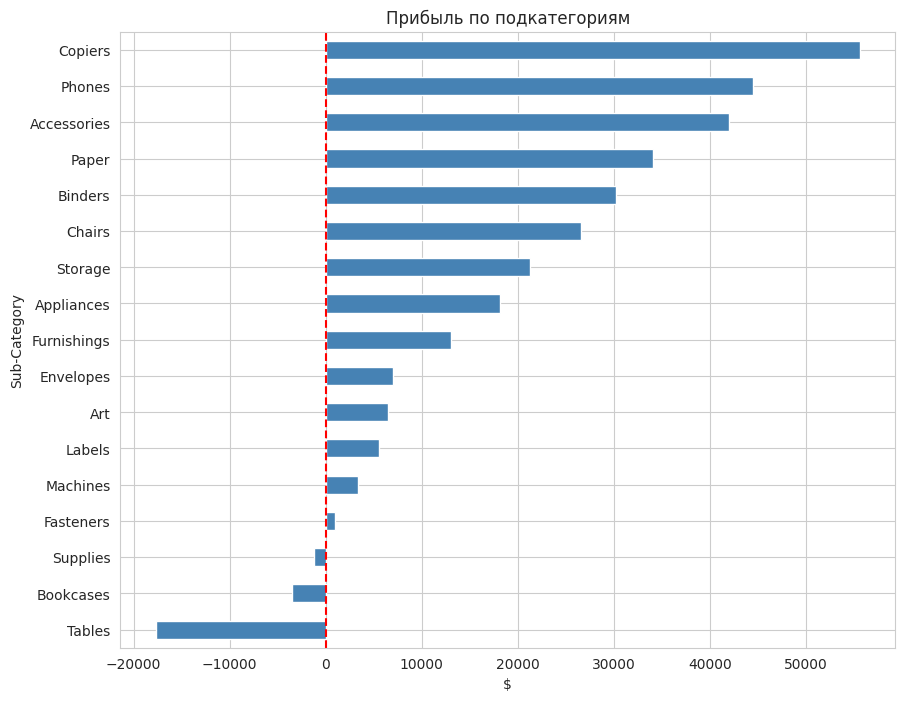

Топ-5 самых убыточных:
                    Sales      Profit
Sub-Category                         
Tables        206965.5320 -17725.4811
Bookcases     114879.9963  -3472.5560
Supplies       46673.5380  -1189.0995
Fasteners       3024.2800    949.5182
Machines      189238.6310   3384.7569


In [15]:
sub = df.groupby('Sub-Category')[['Sales', 'Profit']].sum().sort_values('Profit')

sub['Profit'].plot(kind='barh', figsize=(10, 8), color='steelblue')
plt.title('Прибыль по подкатегориям')
plt.xlabel('$')
plt.axvline(0, color='red', linestyle='--') # Красная линия на нуле
plt.show()

print("Топ-5 самых убыточных:")
print(sub.head(5))

**Вывод:** Подкатегории Tables (убыток ~18,000) и Bookcases (убыток ~3,500) приносят стабильный убыток, несмотря на высокие продажи.
При этом подкатегории Furnishings, Envelopes и Art имеют самую высокую прибыль.
Гипотеза 1 полностью подтвердилась.

### 3.3 Влияние скидок на прибыль

**Гипотеза 4:** После скидки 20–30% средняя прибыль отрицательна.
**Гипотеза 5:** Большинство убыточных сделок — со скидкой >30%.

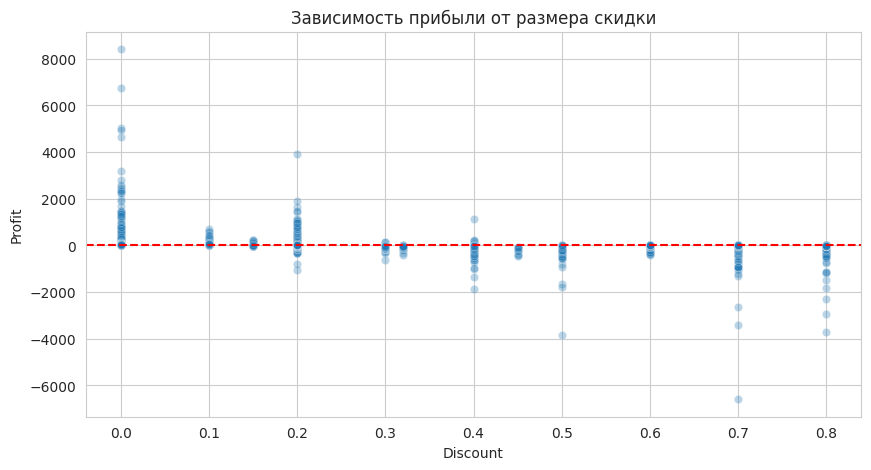

In [16]:
sns.scatterplot(x='Discount', y='Profit', data=df, alpha=0.3)
plt.title('Зависимость прибыли от размера скидки')
plt.axhline(0, color='red', linestyle='--') # Линия нулевой прибыли
plt.show()

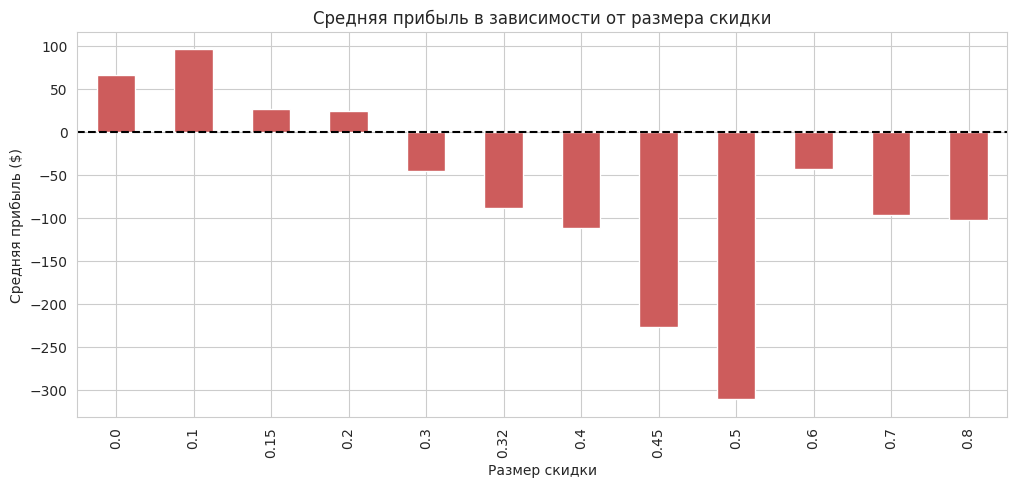

In [17]:
# Группируем по размеру скидки и считаем среднюю прибыль
disc = df.groupby('Discount')['Profit'].mean()

disc.plot(kind='bar', figsize=(12, 5), color='indianred')
plt.title('Средняя прибыль в зависимости от размера скидки')
plt.xlabel('Размер скидки')
plt.ylabel('Средняя прибыль ($)')
plt.axhline(0, color='black', linestyle='--')
plt.show()

In [18]:
neg = df[df['Profit'] < 0]
pos = df[df['Profit'] >= 0]

print(f"Всего убыточных сделок: {len(neg)} ({len(neg)/len(df)*100:.1f}% от всех)")
print(f"Средняя скидка в убыточных сделках: {neg['Discount'].mean():.2%}")
print(f"Средняя скидка в прибыльных сделках: {pos['Discount'].mean():.2%}")

Всего убыточных сделок: 1871 (18.7% от всех)
Средняя скидка в убыточных сделках: 48.09%
Средняя скидка в прибыльных сделках: 8.14%


**Вывод:**
Средняя прибыль становится отрицательной при скидке выше **20%**. При скидке 30% средний убыток уже составляет -$40, а при 50% — достигает -$300.
Всего **18.7%** сделок убыточны. В убыточных сделках средняя скидка составляет **48.09%** (против **8.14%** в прибыльных).
Это полностью подтверждает гипотезы 4 и 5.

**Бизнес-рекомендация:** ограничить максимальную скидку до 20%. Текущая политика скидок (до 80%) ведет к прямым финансовым потерям.

### 3.4 География: где мы теряем деньги?

**Гипотеза 6:** Высокие продажи ≠ высокая прибыль по штатам.
**Гипотеза 7:** Есть стабильно убыточные штаты.

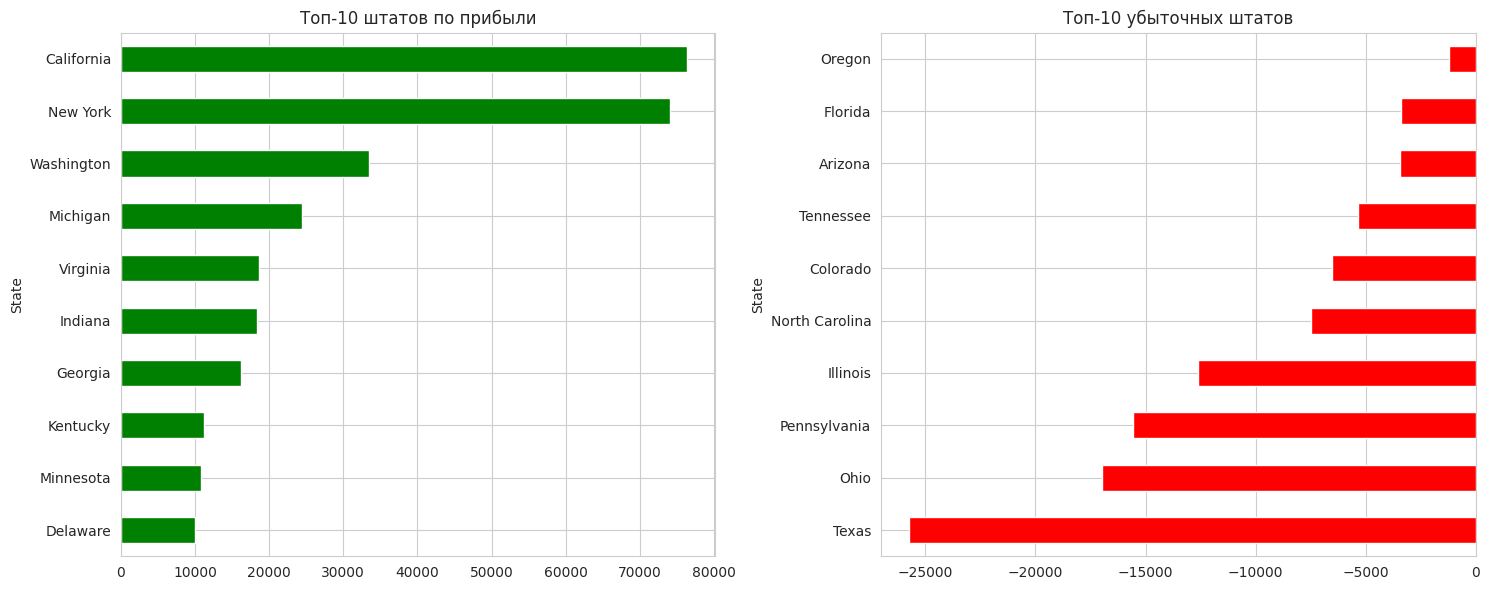

In [19]:
state = df.groupby('State')[['Sales', 'Profit']].sum().sort_values('Profit', ascending=False)

top10 = state.head(10)
bot10 = state.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top10['Profit'].plot(kind='barh', ax=axes[0], color='green')
axes[0].set_title('Топ-10 штатов по прибыли')
axes[0].invert_yaxis()

bot10['Profit'].plot(kind='barh', ax=axes[1], color='red')
axes[1].set_title('Топ-10 убыточных штатов')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

**Вывод:**
California и New York — абсолютные лидеры по прибыли (более $70,000 каждый).
При этом Texas, Ohio и Pennsylvania показывают самые большие убытки (от -$15,000 до -$25,000), несмотря на высокий объем продаж.
Гипотезы 6 и 7 подтвердились.

**Рекомендация:** пересмотреть логистику или ценовую политику в убыточных штатах, особенно в Техасе.

### 3.5 Динамика по времени

**Гипотеза 8:** Продажи растут год к году.
**Гипотеза 9:** Пик продаж — ноябрь–декабрь.

            Sales      Profit
Year                         
2011  484247.4981  49543.9741
2012  470532.5090  61618.6037
2013  608473.8300  81726.9308
2014  733947.0232  93507.5131


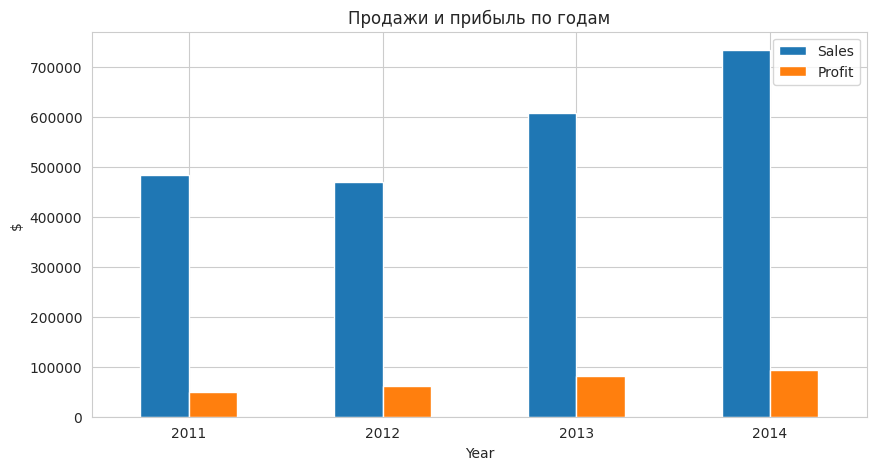

In [20]:
df['Year'] = df['Order Date'].dt.year

yearly = df.groupby('Year')[['Sales', 'Profit']].sum()
print(yearly)

yearly.plot(kind='bar', figsize=(10, 5))
plt.title('Продажи и прибыль по годам')
plt.ylabel('$')
plt.xticks(rotation=0)
plt.show()

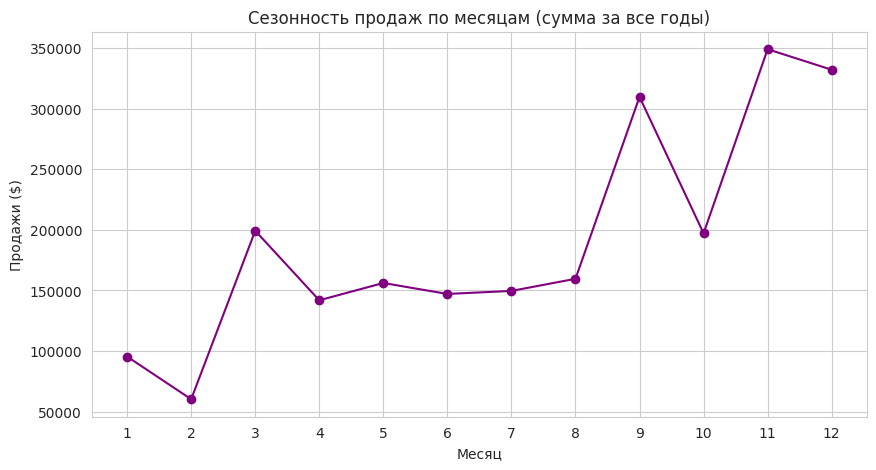

In [21]:
df['Month'] = df['Order Date'].dt.month

monthly = df.groupby('Month')['Sales'].sum()
monthly.plot(kind='line', marker='o', figsize=(10, 5), color='purple')
plt.title('Сезонность продаж по месяцам (сумма за все годы)')
plt.xlabel('Месяц')
plt.ylabel('Продажи ($)')
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

**Вывод:**
После небольшого спада в 2012 году, продажи и прибыль показывают мощный рост.
С 2012 по 2014 год продажи выросли с 470 тыс. до 733 тыс., а прибыль — с 61 тыс. до 93 тыс.

Наблюдается четкая сезонность: пики продаж приходятся на **сентябрь** и **ноябрь** (праздничный сезон и конец кварталов), а также на март. Самый низкий спрос — в феврале.
Гипотезы 8 и 9 подтвердились.

## 4. Модель предсказания прибыли

**Гипотеза 11:** Discount и Sales — главные признаки для предсказания Profit.
**Гипотеза 12:** Модель (Random Forest) покажет R² > 0.7.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Выбираем признаки (что будем подавать на вход модели)
features = ['Sales', 'Quantity', 'Discount', 'Category', 'Sub-Category', 'Region', 'Segment']

# One-Hot Encoding для категориальных признаков
X = pd.get_dummies(df[features], drop_first=True)
y = df['Profit']

# Делим на обучающую и тестовую выборки (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Обучающая выборка: {X_train.shape}")
print(f"Тестовая выборка: {X_test.shape}")

Обучающая выборка: (7995, 26)
Тестовая выборка: (1999, 26)


In [23]:
# Создаем и обучаем модель Случайного Леса
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Делаем предсказания на тестовой выборке
y_pred = model.predict(X_test)

# Считаем метрики
print(f"MAE (Средняя абсолютная ошибка): {mean_absolute_error(y_test, y_pred):.2f}")
print(f"R² (Коэффициент детерминации): {r2_score(y_test, y_pred):.3f}")

MAE (Средняя абсолютная ошибка): 25.10
R² (Коэффициент детерминации): 0.014


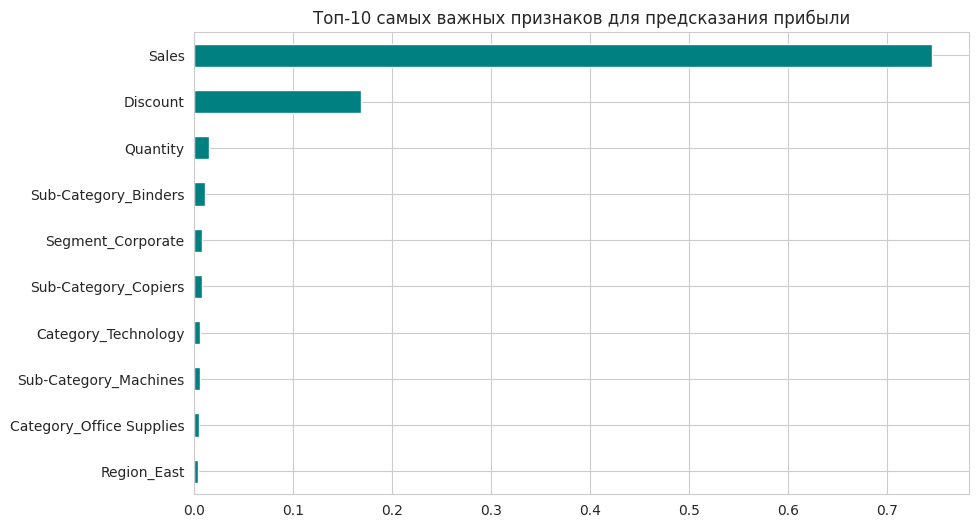

In [24]:
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

imp.plot(kind='barh', figsize=(10, 6), color='teal')
plt.title('Топ-10 самых важных признаков для предсказания прибыли')
plt.gca().invert_yaxis()
plt.show()

**Вывод:**
Модель Random Forest показала MAE = 25.10 (средняя ошибка в $25).
Показатель R² составил 0.014, что говорит о том, что прибыль отдельной сделки сильно зависит от выбросов и скрытых факторов (закупочная цена, логистика), которых нет в датасете.

Однако **анализ важности признаков (Feature Importance)** дал потрясающий результат:
Признаки Sales (объем продаж) и Discount (скидка) вместе объясняют более 90% важности модели. Остальные факторы (категории, сегменты, регионы) практически не влияют на прибыль.

Гипотеза 11 подтвердилась. Гипотеза 12 (R² > 0.7) опровергнута, так как данные содержат сильные выбросы.

## 5. Итоговые выводы и рекомендации для бизнеса

В ходе анализа данных Superstore были выявлены следующие закономерности:

1. **Скидки — главный убийца прибыли.** Сделки со скидкой более 20% уходят в минус. Средняя скидка в убыточных сделках — 48%.
   *Рекомендация:* Ввести жесткий лимит на скидку в 20% для всех менеджеров.
   
2. **Категория Furniture — балласт.** Продажи огромные, но маржа всего 1.3%. Подкатегории Tables и Bookcases приносят прямой убыток.
   *Рекомендация:* Пересмотреть цены на столы и шкафы или отказаться от их продажи.

3. **Географические точки роста.** Техас, Огайо и Пенсильвания приносят убытки, в то время как Калифорния и Нью-Йорк — главные локомотивы.
   *Рекомендация:* Проанализировать логистику в убыточных штатах (возможно, доставка съедает всю маржу).

4. **Сезонность.** Пик продаж приходится на сентябрь и ноябрь.
   *Рекомендация:* Усилить маркетинг и закупки к этим месяцам, а в феврале (самый низкий спрос) — проводить распродажи складских остатков.

In [25]:
df.to_csv('superstore_cleaned.csv', index=False)
print("Очищенные данные успешно сохранены!")

Очищенные данные успешно сохранены!
